In [3]:
#import libraries 
import os
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )


In [7]:
df[['job_title_short','job_skills']].head(5).explode('job_skills')

,job_title_short,job_skills
0,Senior Data Engineer,NaN
1,Data Analyst,r
1,Data Analyst,python
1,Data Analyst,sql
1,Data Analyst,nosql
1,Data Analyst,power bi
1,Data Analyst,tableau
2,Data Engineer,python
2,Data Engineer,sql
2,Data Engineer,c#


In [9]:
df_exploded=df.explode('job_skills')

<Axes: xlabel='job_skills'>

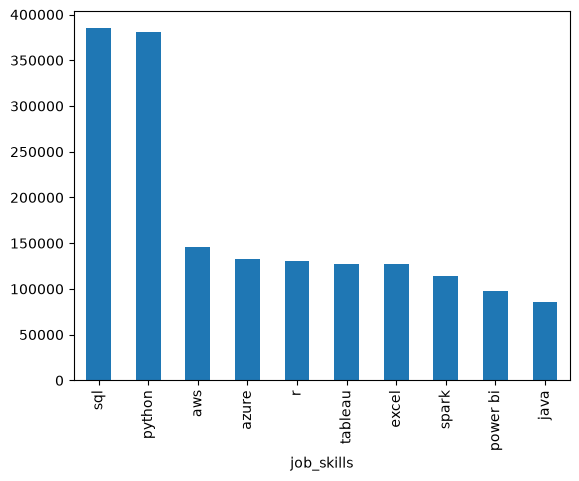

In [11]:
df_exploded['job_skills'].value_counts().head(10).plot(kind='bar')

In [13]:
skills_cont=df_exploded.groupby(['job_title_short','job_skills']).size()
type(skills_cont)

pandas.Series

In [18]:
df_skills_count=skills_cont.reset_index(name='skills_cont')
df_skills_count=df_skills_count.sort_values(by='skills_cont',ascending=False)
df_skills_count

,job_title_short,job_skills,skills_cont
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
462,Data Analyst,chainer,1
432,Cloud Engineer,wrike,1
410,Cloud Engineer,theano,1
24,Business Analyst,chainer,1


In [23]:
job_title='Data Scientist'
top_skills=10 

df_skill_final=df_skills_count[df_skills_count['job_title_short']==job_title].head(top_skills)
df_skill_final

,job_title_short,job_skills,skills_cont
1066,Data Scientist,python,113711
1101,Data Scientist,sql,78982
1070,Data Scientist,r,59566
1082,Data Scientist,sas,29534
1113,Data Scientist,tableau,29445
924,Data Scientist,aws,26256
1096,Data Scientist,spark,24286
925,Data Scientist,azure,21664
1114,Data Scientist,tensorflow,19153
968,Data Scientist,excel,17545


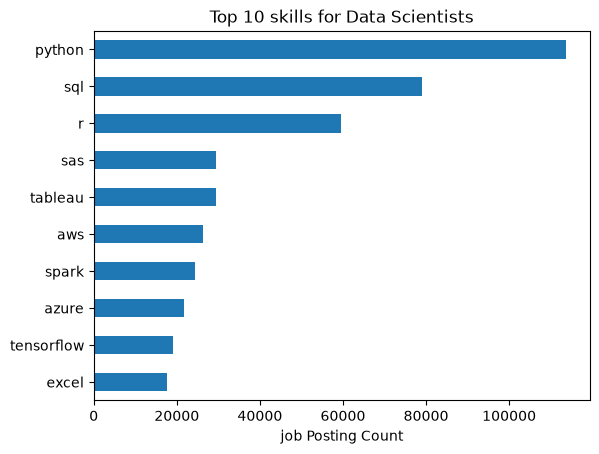

In [25]:
df_skill_final.plot(kind='barh',x='job_skills',y='skills_cont')
plt.gca().invert_yaxis()
plt.title(f'Top {top_skills} skills for {job_title}s')
plt.xlabel('job Posting Count')
plt.ylabel('')
plt.legend().set_visible(False)
plt.show()